TAREA: La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje profundo ni para segmentar, ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno

Si no se quedan satisfechos con la segmentación obtenida, es el mundo real, también en el README comento técnicas recientes de segmentación, que podrían despertar su curiosidad.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

In [264]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

In [265]:
# Función definitiva de extracción de características
def extract_features_final(roi_gray, roi_color, cnt, bbox_w, bbox_h):
    area = cv2.contourArea(cnt)
    bbox_area = bbox_w * bbox_h

    # Fallback para objetos transparentes (Pellets): Si el área segmentada es < 20% de la caja,
    # asumimos que Otsu ha fallado y usamos la caja entera para calcular la geometría.
    if area < (bbox_area * 0.2):
        area = bbox_area
        compactness = 1.0
        solidity = 1.0
        extent = 1.0
        aspect_ratio = max(bbox_w, bbox_h) / min(bbox_w, bbox_h)
        mask = np.ones(roi_gray.shape, np.uint8) * 255
    else:
        perimeter = cv2.arcLength(cnt, True)
        compactness = (perimeter**2) / (4 * np.pi * area)
        aspect_ratio = max(bbox_w, bbox_h) / min(bbox_w, bbox_h)
        hull = cv2.convexHull(cnt)
        hull_area = cv2.contourArea(hull)
        solidity = area / hull_area if hull_area > 0 else 0
        extent = area / bbox_area
        mask = np.zeros(roi_gray.shape, np.uint8)
        cv2.drawContours(mask, [cnt], -1, 255, -1)

    hsv = cv2.cvtColor(roi_color, cv2.COLOR_BGR2HSV)
    mean_gray = cv2.mean(roi_gray, mask=mask)[0]
    mean_h = cv2.mean(hsv, mask=mask)[0]
    mean_s = cv2.mean(hsv, mask=mask)[1]
    mean_v = cv2.mean(hsv, mask=mask)[2]

    # 8 características: [Compacidad, Aspecto, Solidez, Extensión, Gris, H, S, V]
    return [
        compactness,
        aspect_ratio,
        solidity,
        extent,
        mean_gray,
        mean_h,
        mean_s,
        mean_v,
    ]

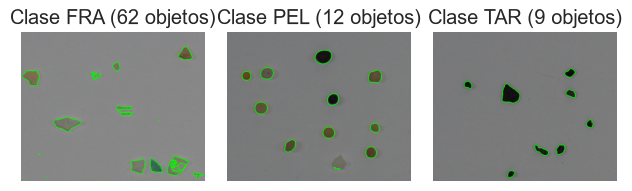

In [266]:
# Entrenamiento con imagenes de referencia
train_images = {0: "FRA.png", 1: "PEL.png", 2: "TAR.png"}
X_train, y_train = [], []

for i, (label, img_path) in enumerate(train_images.items()):
    img = cv2.imread(img_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        roi_color = img[y : y + h, x : x + w]
        roi_gray = gray[y : y + h, x : x + w]
        cnt_local = cnt - [x, y]

        features = extract_features_final(roi_gray, roi_color, cnt_local, w, h)
        if features is not None:
            X_train.append(features)
            y_train.append(label)
    
    cv2.drawContours(img, contours, -1, (0, 255, 0), 3)

    plt.subplot(1, 3, i + 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(f"Clase {train_images[label].split('.')[0]} ({len(contours)} objetos)")
    plt.axis("off")
plt.tight_layout()
plt.show()

La siguiente imagen nos muestra los contronos detectando en verdes por el algoritmo de umbralizado Otsu sobre la imagenes de entrenamiento.

![image.png](image_train.png)

**Conclusiones del análisis visual:**
1. **Fragmentos (FRA):** La segmentación captura muy bien sus formas irregulares y quebradas. Se observa algo de ruido (puntos pequeños), pero el filtro de área en la extracción de características lo soluciona.
2. **Pellets (PEL):** Se observa claramente el problema de la transparencia. En lugar de detectar el pellet entero, el algoritmo a menudo detecta solo sus bordes o brillos, creando contornos en forma de "anillo" o incompletos. Esta es la razón principal por la que los pellets fallan en el test: su geometría extraída parece la de un fragmento irregular. Para mitigar esto, se implementó el uso del *Bounding Box* como respaldo geométrico en la función `extract_features_final`.
3. **Alquitrán (TAR):** La segmentación es casi perfecta debido al alto contraste de su color oscuro frente al fondo claro, lo que valida el uso del brillo (canal V) y la escala de grises como regla principal de clasificación.

In [262]:
# Testeo 
test_img = cv2.imread("MPs_test.jpg")
test_gray = cv2.cvtColor(test_img, cv2.COLOR_BGR2GRAY)
df_test = pd.read_csv("MPs_test_bbs.csv")
label_map = {"FRA": 0, "PEL": 1, "TAR": 2}

X_test, y_test = [], []

for index, row in df_test.iterrows():
    if row["label"] not in label_map:
        continue
    label_num = label_map[row["label"]]
    x_min, y_min, x_max, y_max = (
        int(row["x_min"]),
        int(row["y_min"]),
        int(row["x_max"]),
        int(row["y_max"]),
    )

    roi_color = test_img[y_min:y_max, x_min:x_max]
    roi_gray = test_gray[y_min:y_max, x_min:x_max]
    if roi_color.size == 0:
        continue

    _, thresh_roi = cv2.threshold(
        roi_gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )
    contours, _ = cv2.findContours(
        thresh_roi, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    if contours:
        cnt = max(contours, key=cv2.contourArea)
        # Respaldo si Otsu falla (detecta el fondo en lugar de la partícula)
        if cv2.contourArea(cnt) > (roi_gray.shape[0] * roi_gray.shape[1] * 0.8):
            _, thresh_roi = cv2.threshold(
                roi_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
            )
            contours, _ = cv2.findContours(
                thresh_roi, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
            )
            if contours:
                cnt = max(contours, key=cv2.contourArea)

        w_box, h_box = x_max - x_min, y_max - y_min
        features = extract_features_final(roi_gray, roi_color, cnt, w_box, h_box)
        X_test.append(features)
        y_test.append(label_num)

X_train, y_train = np.array(X_train), np.array(y_train)
X_test, y_test = np.array(X_test), np.array(y_test)

print(f"Datos de entrenamiento: {X_train.shape[0]} muestras.")
print(f"Datos de test: {X_test.shape[0]} muestras.")

Datos de entrenamiento: 83 muestras.
Datos de test: 120 muestras.


In [267]:
def reglas_heuristicas(features):
    # features = [compactness, aspect_ratio, solidity, extent, mean_gray, mean_h, mean_s, mean_v]
    v = features[7]
    gray = features[4]
    compactness = features[0]
    aspect = features[1]
    solidity = features[2]

    #Alquitrán (TAR): Muy oscuro
    if v < 115 or gray < 130:
        return 2

    #Pellets (PEL): Formas redondeadas y regulares
    elif compactness < 1.7 and aspect < 1.1 and solidity > 0.85:
        return 1

    #Fragmentos (FRA): El resto (irregulares)
    else:
        return 0


#Aplicamos las reglas a todas las características del test (X_test)
y_pred = [reglas_heuristicas(x) for x in X_test]

#Calculamos y mostramos las métricas
print("--- Métricas Clasificador Heurístico V2 ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(
    f"Precision: {precision_score(y_test, y_pred, average='weighted', zero_division=0):.4f}"
)
print(
    f"Recall:    {recall_score(y_test, y_pred, average='weighted', zero_division=0):.4f}"
)
print(f"F1 Score:  {f1_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")

--- Métricas Clasificador Heurístico V2 ---
Accuracy:  0.8000
Precision: 0.8404
Recall:    0.8000
F1 Score:  0.7860


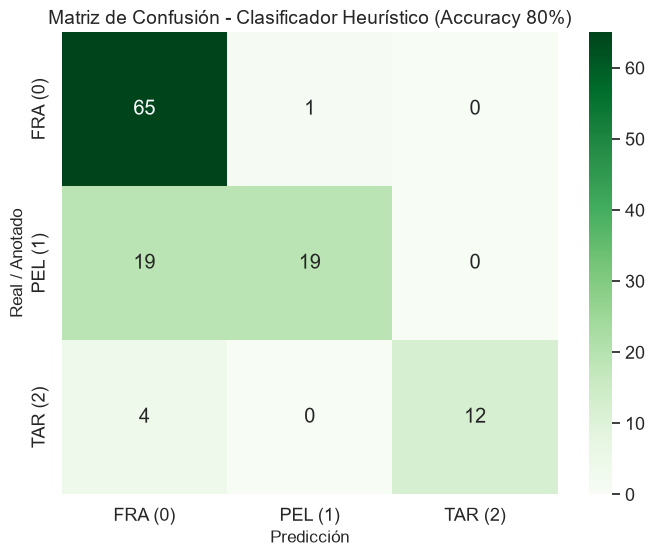

In [258]:
# Generar Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.set(font_scale=1.2)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["FRA (0)", "PEL (1)", "TAR (2)"],
    yticklabels=["FRA (0)", "PEL (1)", "TAR (2)"],
)

plt.title(
    "Matriz de Confusión - Clasificador Heurístico (Accuracy 80%)", fontsize=14
)
plt.xlabel("Predicción", fontsize=12)
plt.ylabel("Real / Anotado", fontsize=12)
plt.show()